<a href="https://colab.research.google.com/github/theresiakatandaja-bit/COU07506-labs-/blob/main/COU07506__week01_%3C24034426286%3E_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Week1
Lab01
Theresia Edward Katandaja
24034426286
24/11/2026
Group no: 4


Pre-lab question: list three devices you used today that contain DSP, and for each name one signal it processes.
Answer:
The devices used and their signals are as follow
1: smartphone - it produces audio signals
2: ECG machine- ECG signal
3: pulse oximeter -it produces PPG signals

Task 1.1

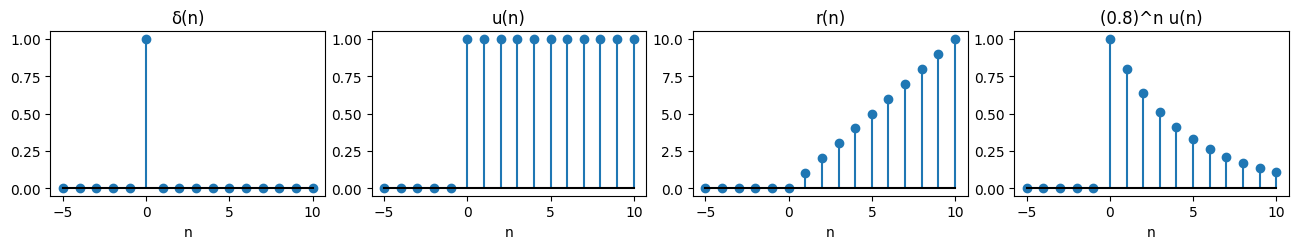

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

Analysis question
1.Why is a stem plot more appropriate than a continuous line for 𝑥(𝑛)?

ANSWER: A stem plot is more appropriate for discrete-time signals because it shows individual sample values at specific integer time indices. A continuous line may suggest that the signal exists at every instant of time, which is not the case for a discrete-time signal.

Task 1.2 change parameters
1.Plot (𝑎)𝑛𝑢(𝑛) for 𝑎 = 0.5, 𝑎 = −0.8 and 𝑎 = 1.1 on one figure using subplots.

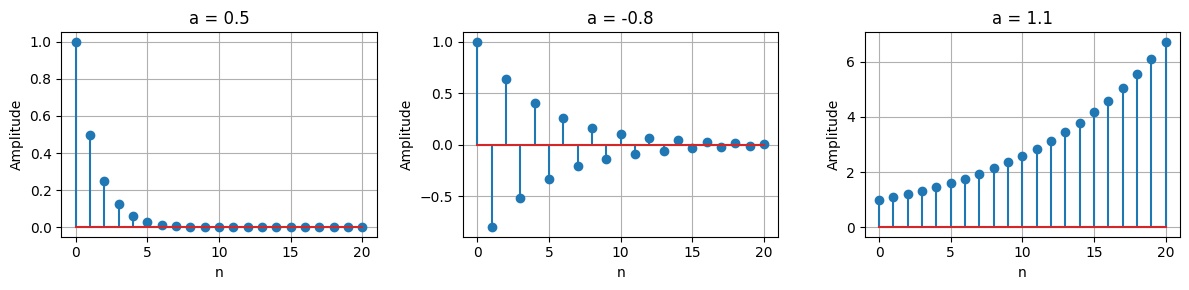

In [ ]:
n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, a_values):
    x = a**n
    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()

Task 1.2 (1) explanation from the graphs

When a=0.5  decaying exponential
When a=-0.8 alternating and decaying
When a=1.1 growing exponential

Analysis questions 3:3.
For 𝑎 = 1.1 the exponential grows. Which property of a system would such a signal violate if it
were an impulse response (Unit 1 §1.7)?

ANSWER:The system would violate the BIBO stability property. This is because the exponential impulse response grows without bound when a=1.1 its absolute sum is infinite; therefore, the system is not BIBO stable

Task 1.2
2. Plot cos(2𝜋𝑛/8) and cos(2𝜋𝑛/7.5) for 0 ≤ 𝑛 ≤ 40. Which one repeats exactly?

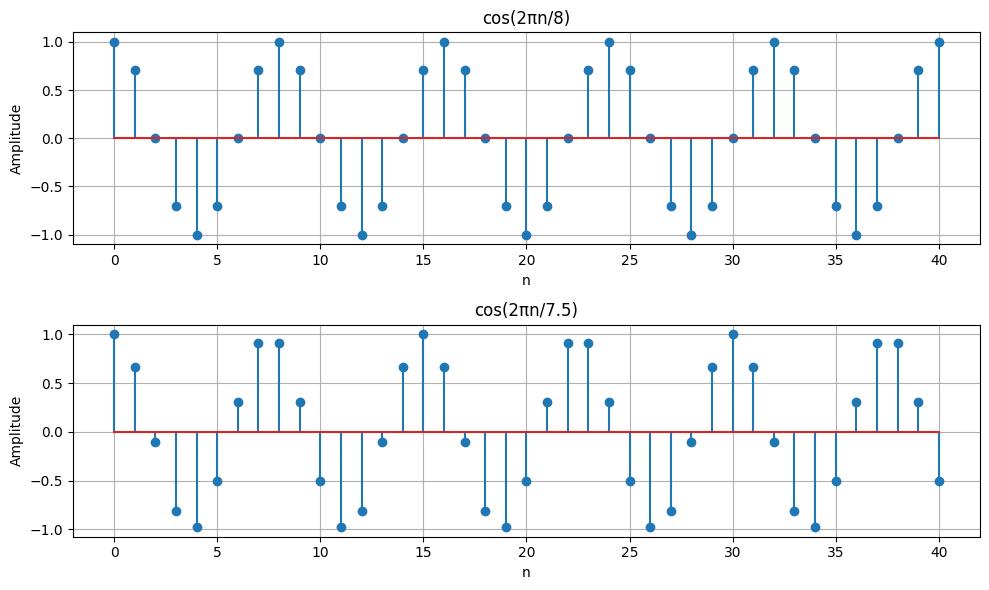

In [ ]:
n = np.arange(0, 41)

x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1)
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].stem(n, x2)
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

Task 1.2
2. Which one repeats exactly?
Answer:
First signal repeats after 8 samples.
Second signal repeats after 15 samples.
Both signals are periodic.

Task 1.3 — Working with audio

fs = 16000 Hz, duration = 2.00 s, samples = 32000


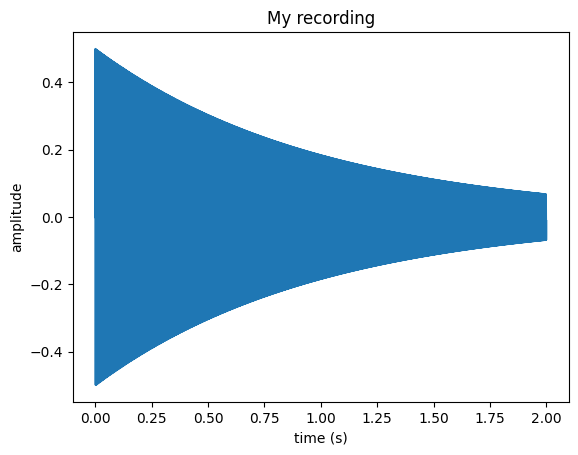

In [ ]:
import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x / np.max(np.abs(x))

else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs

print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Analysis questions 1: What is the sampling rate o your phone’s recording? How many numbers are needed to store one minute of it in mono?

ANSWER: